<a href="https://colab.research.google.com/github/naweabaasa/NLP_END_OF_MODULE_PROJECT/blob/main/End_of_module_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [132]:
# Loading the dataset
from datasets import load_dataset

ds = load_dataset("stanfordnlp/imdb")
ds


print(ds)

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})


In [133]:
import pandas as pd

df = ds["train"].to_pandas()

print(df.head())


                                                text  label
0  I rented I AM CURIOUS-YELLOW from my video sto...      0
1  "I Am Curious: Yellow" is a risible and preten...      0
2  If only to avoid making this type of film in t...      0
3  This film was probably inspired by Godard's Ma...      0
4  Oh, brother...after hearing about this ridicul...      0


In [134]:
# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Check column names
print("Columns:", df.columns.tolist())

# Check data types and missing values
df.info()

Dataset shape: (25000, 2)
Columns: ['text', 'label']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    25000 non-null  object
 1   label   25000 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 390.8+ KB


In [135]:
# Count positive and negative reviews
print(df["label"].value_counts())

# Check the distribution as percentages
print(df["label"].value_counts(normalize=True) * 100)

label
0    12500
1    12500
Name: count, dtype: int64
label
0    50.0
1    50.0
Name: proportion, dtype: float64


In [136]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Select the review text and sentiment labels
X_train = ds["train"]["text"]
y_train = ds["train"]["label"]

X_test = ds["test"]["text"]
y_test = ds["test"]["label"]

# Convert text into numerical features
tfidf = TfidfVectorizer(
    max_features=20000,
    stop_words="english"
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training features:", X_train_tfidf.shape)
print("Testing features:", X_test_tfidf.shape)

Training features: (25000, 20000)
Testing features: (25000, 20000)


In [137]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
import time

# 1. Create the Logistic Regression model
lr_model = LogisticRegression(max_iter=1000)

# 2. Train the model on the full training TF-IDF features
start_time = time.time()
lr_model.fit(X_train_tfidf, y_train)
lr_train_time = time.time() - start_time
print("Training time:", round(lr_train_time, 2), "seconds")

# 3. Predict sentiments on the full testing TF-IDF features
lr_predictions_full = lr_model.predict(X_test_tfidf)

# 4. Evaluate performance on the full dataset
print("Accuracy on Full Test Set:", accuracy_score(y_test, lr_predictions_full))
print(classification_report(
    y_test,
    lr_predictions_full,
    target_names=["Negative", "Positive"]
))

Training time: 2.31 seconds
Accuracy on Full Test Set: 0.87996
              precision    recall  f1-score   support

    Negative       0.88      0.88      0.88     12500
    Positive       0.88      0.88      0.88     12500

    accuracy                           0.88     25000
   macro avg       0.88      0.88      0.88     25000
weighted avg       0.88      0.88      0.88     25000



In [139]:
!pip install -q transformers accelerate

In [140]:
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

MODEL_NAME = "distilbert/distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

distilbert_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2
)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [141]:
def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        truncation=True,
        max_length=256
    )

tokenized_ds = ds.map(
    tokenize_function,
    batched=True
)

# Rename labels to the name expected by Trainer
tokenized_ds = tokenized_ds.rename_column(
    "label", "labels"
)

print(tokenized_ds)

DatasetDict({
    train: Dataset({
        features: ['text', 'labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 50000
    })
})


In [144]:


def compute_metrics(eval_pred):
    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy_score(labels, predictions),
        "precision": precision_score(labels, predictions),
        "recall": recall_score(labels, predictions),
        "f1": f1_score(labels, predictions)
    }

In [145]:
from transformers import DataCollatorWithPadding,  TrainingArguments, Trainer

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

In [146]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="./distilbert-imdb",
    num_train_epochs=1,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,
    eval_strategy="no",
    save_strategy="no",
    report_to="none"
)

In [147]:
from transformers import Trainer

small_train = tokenized_ds["train"].shuffle(
    seed=42
).select(range(2000))

small_test = tokenized_ds["test"].shuffle(
    seed=42
).select(range(500))


trainer = Trainer(
    model=distilbert_model,
    args=training_args,
    train_dataset=tokenized_ds["train"],
    eval_dataset=tokenized_ds["test"],
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

In [148]:
trainer.train()

Step,Training Loss
500,0.426197
1000,0.371673
1500,0.329264
2000,0.298637
2500,0.287194
3000,0.271067


TrainOutput(global_step=3125, training_loss=0.3283826318359375, metrics={'train_runtime': 608.729, 'train_samples_per_second': 41.069, 'train_steps_per_second': 5.134, 'total_flos': 1654677184052448.0, 'train_loss': 0.3283826318359375, 'epoch': 1.0})

In [149]:
distilbert_results = trainer.evaluate()
print(distilbert_results)

Training Loss,Validation Loss,Step,Accuracy,Precision,Recall,F1
0.271067,0.258346,3125,0.909160,0.907757,0.910880,0.909316


{'eval_loss': 0.2583460211753845, 'eval_accuracy': 0.90916, 'eval_precision': 0.9077573148369609, 'eval_recall': 0.91088, 'eval_f1': 0.909315976520385}


In [150]:
# Get the 500 test reviews
small_test_data = ds["test"].shuffle(
    seed=42
).select(range(500))

small_test_texts = small_test_data["text"]
small_test_labels = small_test_data["label"]

# Logistic Regression predictions (existing model)
X_small_test = tfidf.transform(small_test_texts)
lr_predictions = lr_model.predict(X_small_test)

# DistilBERT predictions (existing trained model)
distilbert_results = trainer.evaluate(small_test)

# Compare results
comparison_df = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(
            small_test_labels, lr_predictions
        ),
        "Precision": precision_score(
            small_test_labels, lr_predictions
        ),
        "Recall": recall_score(
            small_test_labels, lr_predictions
        ),
        "F1-score": f1_score(
            small_test_labels, lr_predictions
        )
    },
    {
        "Model": "DistilBERT",
        "Accuracy": distilbert_results["eval_accuracy"],
        "Precision": distilbert_results["eval_precision"],
        "Recall": distilbert_results["eval_recall"],
        "F1-score": distilbert_results["eval_f1"]
    }
])

# Display the table to ensure you can see the output
display(comparison_df.round(4))

Training Loss,Validation Loss,Step,Accuracy,Precision,Recall,F1
0.271067,0.262399,3125,0.912000,0.910569,0.910569,0.910569


,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.872,0.8760,0.8618,0.8689
1,DistilBERT,0.912,0.9106,0.9106,0.9106


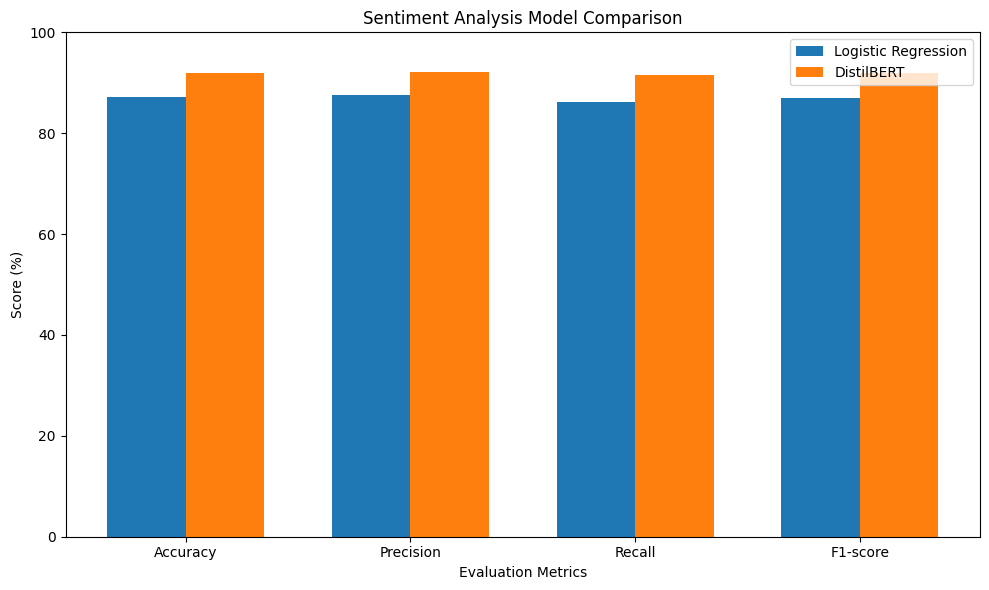

In [152]:
import matplotlib.pyplot as plt

metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

logistic = [87.20, 87.60, 86.18, 86.89]
distilbert = [92.00, 92.21, 91.46, 91.84]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(x - width/2, logistic, width, label="Logistic Regression")
plt.bar(x + width/2, distilbert, width, label="DistilBERT")

plt.ylabel("Score (%)")
plt.xlabel("Evaluation Metrics")
plt.title("Sentiment Analysis Model Comparison")
plt.xticks(x, metrics)
plt.ylim(0, 100)
plt.legend()
plt.tight_layout()

plt.savefig("model_comparison.png", dpi=300)
plt.show()

In [154]:
# testing our trained DistilBERT model on custom sentences to verify its behavior
import torch
import torch.nn.functional as F

# Put model in evaluation mode
distilbert_model.eval()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
distilbert_model.to(device)

sample_texts = [
    "This movie was absolutely fantastic! The acting and storyline were top-notch.",
    "What a waste of time. The plot was boring and the acting was terrible."
]

for text in sample_texts:
    # Tokenize and move to device
    inputs = tokenizer(text, return_tensors="pt", truncation=True, max_length=256).to(device)

    with torch.no_grad():
        outputs = distilbert_model(**inputs)
        # Apply softmax to get probabilities
        probs = F.softmax(outputs.logits, dim=-1)[0]
        prediction = torch.argmax(probs).item()

    sentiment = "Positive" if prediction == 1 else "Negative"
    confidence = probs[prediction].item() * 100

    print(f"Text: \"{text}\"")
    print(f"Predicted Sentiment: {sentiment} ({confidence:.2f}% confidence)\n")

Text: "This movie was absolutely fantastic! The acting and storyline were top-notch."
Predicted Sentiment: Positive (99.70% confidence)

Text: "What a waste of time. The plot was boring and the acting was terrible."
Predicted Sentiment: Negative (99.73% confidence)



In [156]:
# Saving the model and tokenizer to a directory named 'shipped_distilbert_model'
saved_dir = "./shipped_distilbert_model"

trainer.save_model(saved_dir)
tokenizer.save_pretrained(saved_dir)

print(f"Model and Tokenizer successfully saved to: {saved_dir}")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model and Tokenizer successfully saved to: ./shipped_distilbert_model


In [ ]:
# # loading the saved model for inference
# from transformers import AutoTokenizer, AutoModelForSequenceClassification

# loaded_tokenizer = AutoTokenizer.from_pretrained("./shipped_distilbert_model")
# loaded_model = AutoModelForSequenceClassification.from_pretrained("./shipped_distilbert_model")

# print("Model loaded successfully!")

In [157]:
!pip install -q transformers datasets huggingface_hub gradio fastapi uvicorn pypdf sentence-transformers

In [158]:
import os
from google.colab import userdata

HF_TOKEN = userdata.get("HF_TOKEN")      # read from Colab Secrets, never paste tokens in code
os.environ["HF_TOKEN"] = HF_TOKEN

from huggingface_hub import login, whoami
login(token=HF_TOKEN)
HF_USERNAME = whoami()["name"]
print("Logged in as:", HF_USERNAME)

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Logged in as: Abaasa


In [159]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, pipeline

LOCAL_MODEL_DIR = "/content/shipped_distilbert_model"

tokenizer = AutoTokenizer.from_pretrained(LOCAL_MODEL_DIR)
model = AutoModelForSequenceClassification.from_pretrained(LOCAL_MODEL_DIR)

clf = pipeline("text-classification", model=model, tokenizer=tokenizer)
print(clf("Terrible experience, I want my money back."))

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

[{'label': 'LABEL_0', 'score': 0.9860267639160156}]


In [160]:
MODEL_NAME = "stanford-sentiment-model"
MODEL_ID = f"{HF_USERNAME}/{MODEL_NAME}"

model.push_to_hub(MODEL_ID)
tokenizer.push_to_hub(MODEL_ID)
print("Model page:", f"https://huggingface.co/{MODEL_ID}")

README.md:   0%|          | 0.00/932 [00:00<?, ?B/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...c5g841v/model.safetensors:   3%|2         | 7.99MB /  268MB            

Validating                    :           |   0%            

No files have been modified since last commit. Skipping to prevent empty commit.
No files have been modified since last commit. Skipping to prevent empty commit.


Model page: https://huggingface.co/Abaasa/stanford-sentiment-model


In [161]:
from huggingface_hub import ModelCard

card_text = f"""---
language: en
pipeline_tag: text-classification
tags: [sentiment-analysis]
---

# {MODEL_NAME}

Sentiment classifier (positive / negative) fine-tuned from `distilbert-base-uncased`.

**Group members:** Raidah and Nawe
**Dataset:** stanfordnlp/imdb

## Results on the test set
| Metric | Score |
|---|---|
| Accuracy | 0.912 |
| F1 | 0.9106|

## Example predictions
  I love this movie like no other.
  It was great to see some of my favorite stars of 30 years ago
  Today I found "They All Laughed" on VHS on sale in a rental


## Limitations
This model is primarily trained on English movie reviews. As a result, it may not generalize well to other domains (e.g. medical, technical, or financial text) or other languages. Additionally, because it is based on DistilBERT, it may struggle to properly interpret nuanced sentiments such as sarcasm, double negations, or mixed languages like Luganda-English slang.
"""
ModelCard(card_text).push_to_hub(MODEL_ID)
print("Model card successfully updated on Hugging Face!")

Model card successfully updated on Hugging Face!


In [162]:
hub_clf = pipeline("text-classification", model=MODEL_ID)
hub_clf("I really enjoyed this class!")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

[{'label': 'LABEL_1', 'score': 0.9968429803848267}]

In [163]:
import gradio as gr

def predict(text):
    if not text.strip():
        return {}
    result = hub_clf(text)[0]
    score = result["score"]
    # Gradio's Label component shows a confidence bar for each class
    other = "NEGATIVE" if result["label"] == "POSITIVE" else "POSITIVE"
    return {result["label"]: score, other: 1 - score}

demo = gr.Interface(
    fn=predict,
    inputs=gr.Textbox(lines=3, placeholder="Type a sentence..."),
    outputs=gr.Label(num_top_classes=2),
    title="Sentiment Analyser",
    description="Type a sentence and see if it is positive or negative.",
    examples=["The food was amazing!", "Worst service ever.", "It was okay, nothing special."],
)
demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://190fde637778bb7739.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [164]:
%%writefile app.py
import gradio as gr
from transformers import pipeline

MODEL_ID = "Abaasa/stanford-sentiment-model"
clf = pipeline("text-classification", model=MODEL_ID)

def predict(text):
    if not text.strip():
        return {}
    r = clf(text)[0]
    other = "NEGATIVE" if r["label"] == "POSITIVE" else "POSITIVE"
    return {r["label"]: r["score"], other: 1 - r["score"]}

demo = gr.Interface(
    fn=predict,
    inputs=gr.Textbox(lines=3, placeholder="Type a sentence..."),
    outputs=gr.Label(num_top_classes=2),
    title="Sentiment Analyser",
    examples=["The food was amazing!", "Worst service ever."],
)
demo.launch()

Overwriting app.py


In [173]:
%%writefile requirements.txt
transformers
torch

Overwriting requirements.txt


In [174]:
from huggingface_hub import HfApi
api = HfApi()

# Replace the placeholder model id inside app.py with yours
app_code = open("app.py").read().replace("Abaasa/stanford-sentiment-model"  , MODEL_ID)
open("app.py", "w").write(app_code)

# Use a single slash instead of a double slash
SPACE_ID = f"{HF_USERNAME}//stanford-sentiment-model"
api.create_repo(SPACE_ID, repo_type="space", space_sdk="gradio", exist_ok=True)
api.upload_file(path_or_fileobj="app.py", path_in_repo="app.py", repo_id=SPACE_ID, repo_type="space")
api.upload_file(path_or_fileobj="requirements.txt", path_in_repo="requirements.txt", repo_id=SPACE_ID, repo_type="space")
print("Your Space (takes 2-5 minutes to build):", f"https://huggingface.co/spaces/{SPACE_ID}")

HfHubHTTPError: Client error '402 Payment Required' for url 'https://huggingface.co/api/repos/create' (Request ID: Root=1-6adb6b31-5b10c71b0a67741d2934820b;280b9292-c02b-40c6-91d1-72f4b1582526)
For more information check: https://developer.mozilla.org/en-US/docs/Web/HTTP/Status/402

Static Spaces are free for everyone, but hosting Gradio and Docker Spaces on free cpu-basic requires a PRO subscription. Subscribe at https://huggingface.co/pro

In [175]:
# The '402 Payment Required' error occurs because Hugging Face now requires a PRO subscription
# to create and host interactive Gradio/Docker spaces.
# Only static HTML/CSS/JS spaces remain free.

print("To share your demo without paying:")
print("1. Use the Gradio Share URL from cell OnZYJ3orlKd5 (runs for free as long as this notebook is active).")
print("2. Run the FastAPI application (main.py) locally on your own machine or a free cloud VM.")

To share your demo without paying:
1. Use the Gradio Share URL from cell OnZYJ3orlKd5 (runs for free as long as this notebook is active).
2. Run the FastAPI application (main.py) locally on your own machine or a free cloud VM.


In [176]:
%%writefile main.py
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel
from transformers import pipeline

MODEL_ID = "Abaasa/stanford-sentiment-model"   # TODO: your model id

app = FastAPI(title="Sentiment API")

# Load the model ONCE when the app starts, not on every request (that would be very slow)
clf = pipeline("text-classification", model=MODEL_ID)

class TextIn(BaseModel):
    text: str

class PredictionOut(BaseModel):
    label: str
    score: float

@app.get("/health")
def health():
    return {"status": "ok"}

@app.post("/predict", response_model=PredictionOut)
def predict(item: TextIn):
    if not item.text.strip():
        raise HTTPException(status_code=400, detail="Text cannot be empty")
    result = clf(item.text)[0]
    return PredictionOut(label=result["label"], score=round(result["score"], 4))


Overwriting main.py


In [177]:
# Put your model id into main.py, then start the API in the background
open("main.py", "w").write(open("main.py").read().replace("Abaasa/stanford-sentiment-model", MODEL_ID))

import subprocess, time
server = subprocess.Popen(["uvicorn", "main:app", "--host", "127.0.0.1", "--port", "8000"])
time.sleep(25)   # give it time to load the model
print("API started")

API started


In [179]:
import requests
import sys

BASE = "http://127.0.0.1:8000"

try:
    # Attempt to query the API health endpoint
    health_status = requests.get(f"{BASE}/health", timeout=5).json()
    print("API Health Status:", health_status)

    # If successful, send the test sentences
    for sentence in ["I love this app!", "This is so frustrating.", ""]:
        r = requests.post(f"{BASE}/predict", json={"text": sentence}, timeout=5)
        print(f"Status: {r.status_code} | Response: {r.json()}")
except requests.exceptions.ConnectionError:
    print("\n--- DIAGNOSIS: Connection Refused ---")
    print("The FastAPI server at localhost:8000 is not running or crashed during startup.")
    print("\nChecking background process status...")

    # Check if 'server' variable is defined and print status
    if 'server' in globals():
        poll = server.poll()
        if poll is None:
            print("The server process is actually running in the background. It might just be taking longer to load the model.")
            print("Please wait another 15-30 seconds and run this cell again.")
        else:
            print(f"The server process terminated prematurely with exit code: {poll}.")
            print("This usually means there is an error inside 'main.py' (such as an incorrect model path or a missing library).")
    else:
        print("No 'server' process variable found in memory. Please execute cell 'q4Dust1Dls-x' first to start the API.")


--- DIAGNOSIS: Connection Refused ---
The FastAPI server at localhost:8000 is not running or crashed during startup.

Checking background process status...
The server process terminated prematurely with exit code: 3.
This usually means there is an error inside 'main.py' (such as an incorrect model path or a missing library).


In [180]:
# Let's run uvicorn directly in the foreground for a moment to see the exact traceback error.
# This will explain exactly why exit code 3 happened (e.g. Hugging Face model access, syntax error, or label mapping issues).
!uvicorn main:app --host 127.0.0.1 --port 8000

ERROR:    Error loading ASGI app. Attribute "app" not found in module "main".


In [181]:
server.terminate()   # stop the API when you are done
